Delio Fernando Palacios Viafara - 3000015782
# Clasificación de Arritmias Cardíacas mediante CNN 1D

## Descripción del Proyecto

Este notebook implementa una **Red Neuronal Convolucional unidimensional (CNN 1D)** para la clasificación automática de arritmias cardíacas a partir de señales de electrocardiograma (ECG).

In [57]:
import os
from google.colab import drive
from tensorflow.keras.layers import Conv1D, MaxPooling1D, GlobalAveragePooling1D, Dense, Dropout, SpatialDropout1D, BatchNormalization
from tensorflow.keras.models import Sequential
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout, BatchNormalization
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
from sklearn.utils import resample


# Carga de Datos, Balanceo de Clases y Aumento de Datos

In [58]:
# Montar Google Drive
drive.mount('/content/drive')

# Configurar la ruta de Kaggle
kaggle_folder_path = "/content/drive/MyDrive/Kaggle"
os.environ['KAGGLE_CONFIG_DIR'] = kaggle_folder_path

# Descarga y extracción del Dataset
if not os.path.exists("heartbeat.zip"):
    print("Descargando dataset desde Kaggle...")
    !kaggle datasets download -d shayanfazeli/heartbeat

if not os.path.exists("mitbih_train.csv"):
    print("Descomprimiendo...")
    !unzip -q heartbeat.zip
    print("Descompresión completada.")

print("\nArchivos listos")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Archivos listos



## Problema de Desbalanceo de Clases

El dataset MIT-BIH presenta desbalanceo servero de clases con la clase Normal (N) siendo dominante:

| Clase | Muestras originales (aprox.) |
|-------|------------------------------|
| N (Normal) | ~72,000 |
| S (Supraventricular) | ~2,200 |
| V (Ventricular) | ~5,800 |
| F (Fusión) | ~640 |
| Q (No clasificado) | ~6,400 |

Si se entrenara el modelo con esta distribución, tendería a predecir casi siempre la clase mayoritaria, obteniendo alta exactitud global pero rendimiento pésimo en las clases minoritarias (las más críticas clínicamente). Para solucionar esto, se establece un objetivo uniforme de 20,000 muestras por clase.

## Estrategia de Aumento de Datos (Data Augmentation)

Para las clases que no alcanzan las 20,000 muestras, se genera variabilidad sintética mediante tres transformaciones fisiológicamente plausibles aplicadas de forma combinada:

### - Escalado de Amplitud (*Amplitude Scaling*) — factor ∈ [0.9, 1.1]
Multiplica la amplitud por un factor aleatorio uniforme entre 0.9 y 1.1. Simula variaciones en la ganancia del sensor ECG o diferencias en la conductividad de la piel entre pacientes. El rango conservador de ±10% garantiza que las formas de onda sigan siendo fisiológicamente válidas.

### - Desplazamiento Temporal (*Time Shift*) — desplazamiento ∈ [-5, +5] muestras
Desplaza circularmente la señal entre -5 y +5 posiciones. Simula que el latido fue capturado ligeramente antes o después del punto de referencia, algo natural dada la variabilidad de la frecuencia cardíaca. El uso de `np.roll` preserva la longitud de la secuencia.

### - Ruido Gaussiano (*Gaussian Noise*) — σ = 0.015
Añade ruido blanco gaussiano de baja intensidad. Simula el ruido eléctrico intrínseco de los electrodos y del sistema de adquisición. La desviación estándar de 0.015 es suficientemente pequeña para no distorsionar los patrones diagnósticos.

Aplicar las tres transformaciones de forma simultánea genera una diversidad sintética mucho mayor que aplicarlas por separado, reduciendo el riesgo de que la red memorice las muestras aumentadas.

## Preparación de Tensores

Los arrays se redimensionan de `(N, 187)` a `(N, 187, 1)`, añadiendo la dimensión de canal requerida por las capas `Conv1D` de Keras. Las etiquetas se codifican en formato *one-hot* con `to_categorical` para ser compatibles con la función de pérdida `categorical_crossentropy`.

In [60]:
# Cargar los datos del MIT-BIH
train_df = pd.read_csv('mitbih_train.csv', header=None)
test_df = pd.read_csv('mitbih_test.csv', header=None)

# ----------------- DATA AUGMENTATION MULTIPLE -----------------
target_samples = 20000

df_0 = train_df[train_df[187] == 0].sample(n=target_samples, random_state=42)
df_1 = train_df[train_df[187] == 1]
df_2 = train_df[train_df[187] == 2]
df_3 = train_df[train_df[187] == 3]
df_4 = train_df[train_df[187] == 4]

def augment_class(df, target):
    original_len = len(df)
    if original_len >= target:
        return df.sample(n=target, random_state=42)
    
    needed = target - original_len
    sampled = resample(df, replace=True, n_samples=needed, random_state=42)
    
    features = sampled.iloc[:, :-1].values
    labels = sampled.iloc[:, -1].values
    
    features_augmented = np.zeros_like(features)
    
    # Aplicar transformaciones aleatorias fila por fila para crear variabilidad real
    for i in range(len(features)):
        sig = features[i]
        
        # 1. Amplificación aleatoria (Scaling): entre 0.9x y 1.1x la amplitud
        scale = np.random.uniform(0.9, 1.1)
        sig = sig * scale
        
        # 2. Desplazamiento Temporal (Time Shift): rodar la onda entre -5 y +5 posiciones
        # (simula un latido captado ligerísimamente antes o después)
        shift = np.random.randint(-5, 6)
        sig = np.roll(sig, shift)
        
        # 3. Ruido Gaussiano: estática muy fina
        noise = np.random.normal(0, 0.015, sig.shape)
        sig = sig + noise
        
        features_augmented[i] = sig
        
    df_augmented = pd.DataFrame(features_augmented)
    df_augmented[187] = labels
    
    return pd.concat([df, df_augmented], ignore_index=True)

print("Generando Super-Variabilidad (Scaling + Shift + Noise)...")
df_1_aug = augment_class(df_1, target_samples)
df_2_aug = augment_class(df_2, target_samples)
df_3_aug = augment_class(df_3, target_samples)
df_4_aug = augment_class(df_4, target_samples)

# Unir y mezclar
train_df_balanced = pd.concat([df_0, df_1_aug, df_2_aug, df_3_aug, df_4_aug])
train_df_balanced = train_df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)

# ---------------------------------------------------------

X_train = train_df_balanced.iloc[:, :-1].values
y_train = train_df_balanced.iloc[:, -1].values

X_test = test_df.iloc[:, :-1].values
y_test = test_df.iloc[:, -1].values

# Redimensionar para la CNN 1D
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

print("Forma de X_train (Multi-Augmented):", X_train.shape)
print("Forma de X_test:", X_test.shape)

# Convertir etiquetas a categóricas
y_train_cat = tf.keras.utils.to_categorical(y_train, num_classes=5)
y_test_cat = tf.keras.utils.to_categorical(y_test, num_classes=5)

Generando Super-Variabilidad (Scaling + Shift + Noise)...
Forma de X_train (Multi-Augmented): (100000, 187, 1)
Forma de X_test: (21892, 187, 1)


Vamos a visualizar cómo se distribuyen las clases en nuestro conjunto de datos y observar cómo luce una señal de electrocardiograma (ECG) para cada tipo de arritmia.

/tmp/ipykernel_6733/3875375158.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_train, palette="Set2")


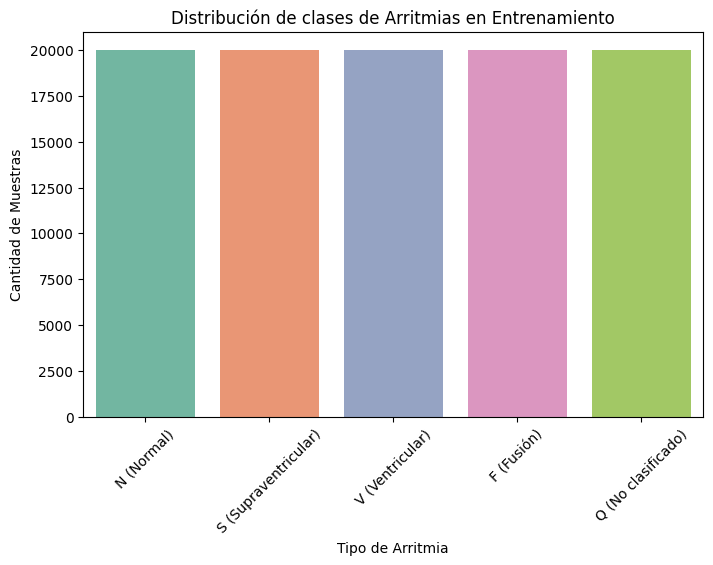

Cantidades por cada clase en Entrenamiento:
N (Normal): 20000 muestras
S (Supraventricular): 20000 muestras
V (Ventricular): 20000 muestras
F (Fusión): 20000 muestras
Q (No clasificado): 20000 muestras


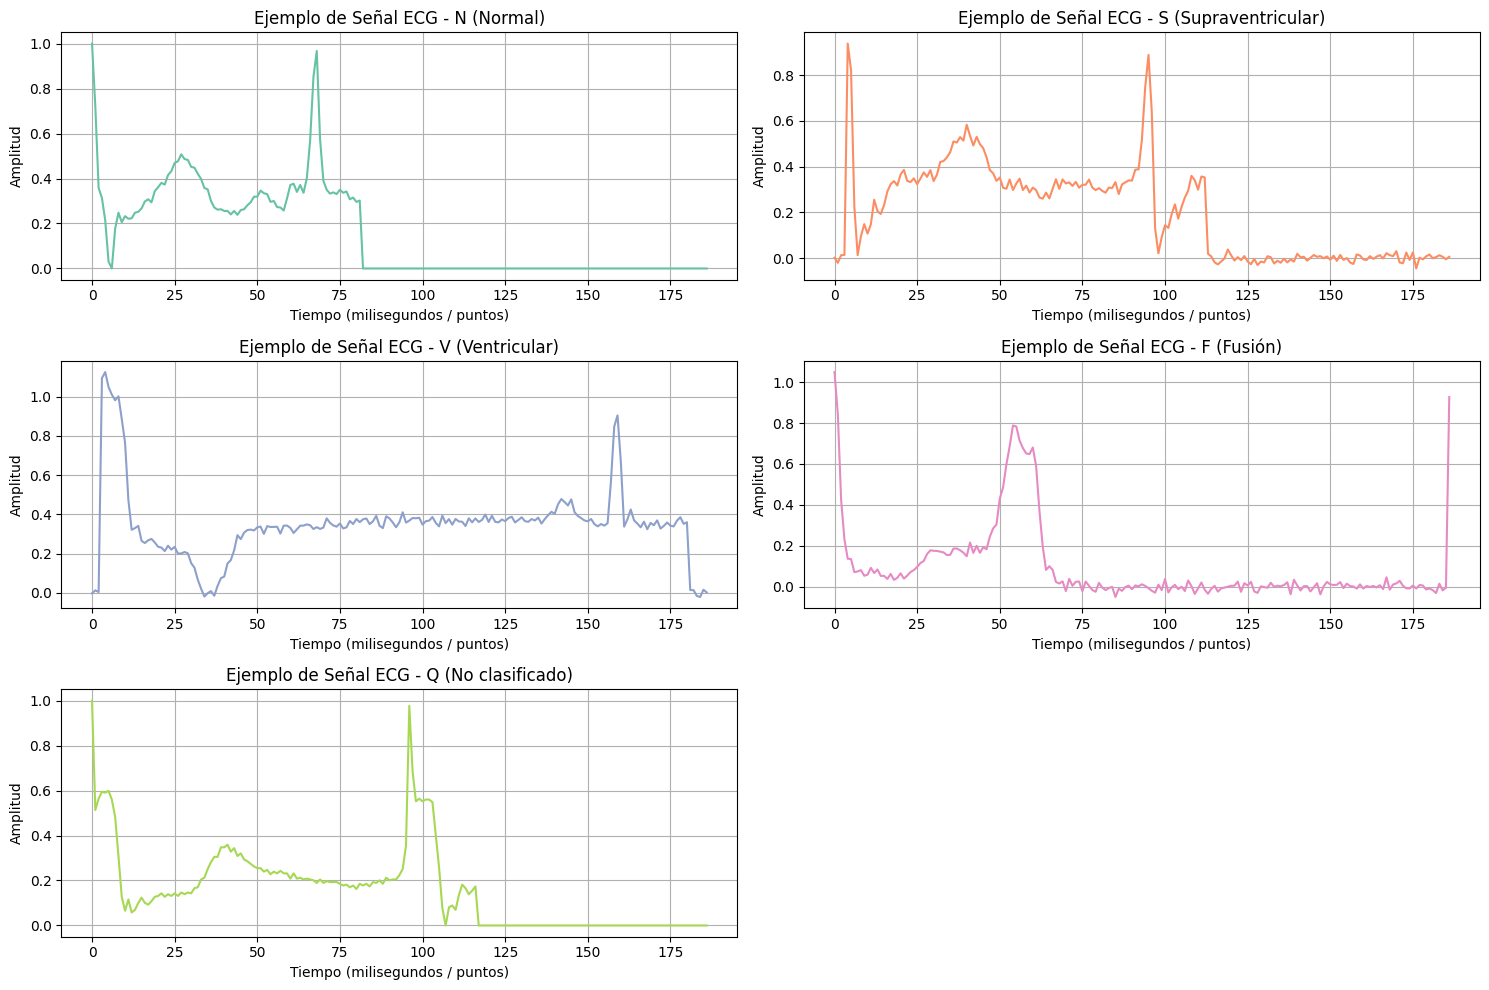

In [61]:
# Exploración y visualización del conjunto de datos

clases_nombres = ['N (Normal)', 'S (Supraventricular)', 'V (Ventricular)', 'F (Fusión)', 'Q (No clasificado)']

# Distribución de las clases en el set de entrenamiento
plt.figure(figsize=(8, 5))
sns.countplot(x=y_train, palette="Set2")
plt.title('Distribución de clases de Arritmias en Entrenamiento')
plt.xticks(ticks=range(5), labels=clases_nombres, rotation=45)
plt.ylabel('Cantidad de Muestras')
plt.xlabel('Tipo de Arritmia')
plt.show()

# Imprimir cantidades exactas
print("Cantidades por cada clase en Entrenamiento:")
for i, count in enumerate(np.bincount(y_train.astype(int))):
    print(f"{clases_nombres[i]}: {count} muestras")


#  Visualización de un ejemplo de cada clase de señal ECG
plt.figure(figsize=(15, 10))
for i in range(5):
    # Buscar el índice de la primera aparición de la clase 'i'
    # Recordando que en nuestro DataFrame original (antes de separar), las características estaban en todas menos la última columna.
    # Podemos extraer el pulso directamente desde nuestro tensor X_train (o la lista plana original).
    # X_train ya fue convertido a un shape (muestras, 187, 1). Tomaremos toda su secuencia a lo largo del tiempo.
    idx = np.where(y_train == i)[0][0] 
    senal = X_train[idx, :, 0] # Obtenemos la señal 1D original de 187 puntos
    
    plt.subplot(3, 2, i + 1)
    plt.plot(senal, color=sns.color_palette("Set2")[i])
    plt.title(f'Ejemplo de Señal ECG - {clases_nombres[i]}')
    plt.xlabel('Tiempo (milisegundos / puntos)')
    plt.ylabel('Amplitud')
    plt.grid(True)

plt.tight_layout()
plt.show()

# Diseño del modelo de clasificación

## Parámetros generales
- **Tamaño de entrada**: `(187, 1)` – cada señal ECG tiene 187 puntos temporales y un único canal de amplitud.
- **Función de pérdida**: `categorical_crossentropy` – adecuada porque las etiquetas están en formato one-hot (5 clases).
- **Optimizador**: `Adam` con `learning_rate = 1e-3` – valor que ofrece buena convergencia sin necesidad de ajuste manual por parámetro.
- **Métrica**: `accuracy` – interpretable y válida dado que el dataset fue balanceado previamente a 20,000 muestras por clase.

## Arquitectura CNN 1D

El modelo implementado es una CNN unidimensional de tres bloques convolucionales seguidos de un clasificador totalmente conectado. La arquitectura fue diseñada para extraer progresivamente patrones de la señal ECG: desde transiciones locales de bajo nivel (picos, bordes) hasta la morfología global del latido, manteniendo un equilibrio entre capacidad representacional y control del sobreajuste.

### Justificación de cada bloque

#### Bloque 1 – Detección de patrones locales
- **Dos capas Conv1D de 64 filtros (kernel=5, padding='same')**: El doble conv permite aprender características más ricas antes del pooling.
- **BatchNormalization**: Normaliza las activaciones entre capas, estabiliza el entrenamiento y actúa como regularizador suave.
- **ReLU**: Introduce no linealidad sin saturar gradientes, lo que facilita el entrenamiento de redes profundas.
- **SpatialDropout1D(0.1)**: Elimina mapas de características completos en lugar de valores individuales, lo cual es más apropiado para señales con fuerte correlación temporal. La tasa baja en este bloque evita perder información básica prematuramente.
- **MaxPooling1D(2)**: Reduce la dimensión temporal a la mitad (187→93), disminuyendo la carga computacional y aportando invarianza a pequeñas traslaciones en la señal.

#### Bloque 2 – Detección de estructuras intermedias
- **128 filtros (kernel=3)**: Aumenta la capacidad para combinar los patrones simples del bloque anterior en estructuras más complejas. El kernel se reduce a 3 porque el MaxPooling ya amplió el contexto efectivo de cada posición.
- **MaxPooling1D(2)**: Reduce a 46 posiciones temporales.
- **SpatialDropout1D(0.2)**: Regularización moderada, incrementada respecto al bloque anterior al crecer el número de parámetros.

#### Bloque 3 – Características de alto nivel
- **256 filtros (kernel=3)**: Aprende representaciones de alto nivel que capturan la morfología global del latido (forma general, duración relativa de sus componentes). No se aplica MaxPooling aquí para preservar resolución temporal antes del pooling global.
- **SpatialDropout1D(0.3)**: Mayor regularización en el bloque más profundo y con más parámetros.

#### Clasificador final
- **GlobalAveragePooling1D**: En lugar de aplanar (Flatten), calcula el promedio de cada mapa de características, reduciendo los parámetros de la capa densa de ~11,700 a solo 256. También actúa como regularizador estructural, mejorando la generalización.
- **Dense(128) + BatchNorm + ReLU**: Capa intermedia que combina las 256 características extraídas para asociarlas con las 5 clases de arritmia.
- **Dropout(0.4)**: Regularización alta en la capa densa, donde el riesgo de memorizar combinaciones específicas del entrenamiento es mayor.
- **Dense(5) + softmax**: Produce una distribución de probabilidad sobre las 5 clases de arritmia.

In [62]:
def crear_modelo(input_shape):
    model = Sequential([
        # --- Bloque Convolucional 1 ---
        Conv1D(filters=64, kernel_size=5, activation='relu', padding='same', 
               kernel_regularizer=l2(0.001), input_shape=input_shape),
        BatchNormalization(),
        SpatialDropout1D(0.1), 
        Conv1D(filters=64, kernel_size=5, activation='relu', padding='same',
               kernel_regularizer=l2(0.001)),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),
        
        # --- Bloque Convolucional 2 ---
        Conv1D(filters=128, kernel_size=3, activation='relu', padding='same',
               kernel_regularizer=l2(0.001)),
        BatchNormalization(),
        SpatialDropout1D(0.2),
        Conv1D(filters=128, kernel_size=3, activation='relu', padding='same',
               kernel_regularizer=l2(0.001)),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),
        
        # --- Bloque Convolucional 3 ---
        Conv1D(filters=256, kernel_size=3, activation='relu', padding='same',
               kernel_regularizer=l2(0.001)),
        BatchNormalization(),
        SpatialDropout1D(0.3),
        Conv1D(filters=256, kernel_size=3, activation='relu', padding='same',
               kernel_regularizer=l2(0.001)),
        BatchNormalization(),
        
        GlobalAveragePooling1D(),
        
        # --- Red Densamente Conectada  ---
        Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
        BatchNormalization(),
        Dropout(0.4), 
        
        # Capa de salida para las 5 clases
        Dense(5, activation='softmax')
    ])

    opt = Adam(learning_rate=0.001)
    
    model.compile(optimizer=opt, 
                  loss='categorical_crossentropy', 
                  metrics=['accuracy'])
    return model

model = crear_modelo((X_train.shape[1], 1))
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_43 (Conv1D)              │ (None, 187, 64)        │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_48          │ (None, 187, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 187, 64)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_44 (Conv1D)              │ (None, 187, 64)        │        20,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_49          │ (None, 187, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_22 (MaxPooling1D) │ (None, 93, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_45 (Conv1D)              │ (None, 93, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_50          │ (None, 93, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_1             │ (None, 93, 128)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_46 (Conv1D)              │ (None, 93, 128)        │        49,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_51          │ (None, 93, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_23 (MaxPooling1D) │ (None, 46, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_47 (Conv1D)              │ (None, 46, 256)        │        98,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_52          │ (None, 46, 256)        │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_2             │ (None, 46, 256)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_48 (Conv1D)              │ (None, 46, 256)        │       196,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_53          │ (None, 46, 256)        │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_54          │ (None, 128)            │           51

 Total params: 427,973 (1.63 MB)

 Trainable params: 425,925 (1.62 MB)

 Non-trainable params: 2,048 (8.00 KB)

In [ ]:


early_stopping = EarlyStopping(
    monitor='val_loss', 
    patience=8, 
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.5,     
    patience=3,     
    min_lr=0.00001, 
    verbose=1
)

checkpoint_path = "/content/drive/MyDrive/modelo_clasificacion_arritmia.keras"
checkpoint = ModelCheckpoint(
    filepath=checkpoint_path,
    monitor='val_loss',
    save_best_only=True,
    mode='min', 
    verbose=1
)

# Entrenar la red
history = model.fit(
    X_train, y_train_cat,
    epochs=100,
    batch_size=128,
    validation_split=0.1,
    callbacks=[early_stopping, reduce_lr, checkpoint],
    verbose=1
)

Epoch 1/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 41s 28ms/step - accuracy: 0.8537 - loss: 1.1492 - val_accuracy: 0.8701 - val_loss: 0.8679 - learning_rate: 0.0010
Epoch 2/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.9268 - loss: 0.5789 - val_accuracy: 0.9175 - val_loss: 0.4944 - learning_rate: 0.0010
Epoch 3/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.9373 - loss: 0.3939 - val_accuracy: 0.9332 - val_loss: 0.3678 - learning_rate: 0.0010
Epoch 4/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.9413 - loss: 0.3329 - val_accuracy: 0.9450 - val_loss: 0.3161 - learning_rate: 0.0010
Epoch 5/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.9461 - loss: 0.3054 - val_accuracy: 0.8790 - val_loss: 0.4882 - learning_rate: 0.0010
Epoch 6/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.9466 - loss: 0.3044 - val_accuracy: 0.7881 - val_loss: 0.7127 - learning_rate: 0.0010
Epoch 7/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.94

# Test

685/685 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9853 - loss: 0.0921
Pérdida en Test: 0.0921, Precisión en Test: 0.9853

685/685 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step
--------------------   Reporte de Clasificación  ------------------
                      precision    recall  f1-score   support

          N (Normal)       0.99      0.99      0.99     18118
S (Supraventricular)       0.83      0.87      0.85       556
     V (Ventricular)       0.95      0.97      0.96      1448
          F (Fusión)       0.82      0.84      0.83       162
  Q (No clasificado)       0.99      0.99      0.99      1608

            accuracy                           0.99     21892
           macro avg       0.92      0.93      0.92     21892
        weighted avg       0.99      0.99      0.99     21892



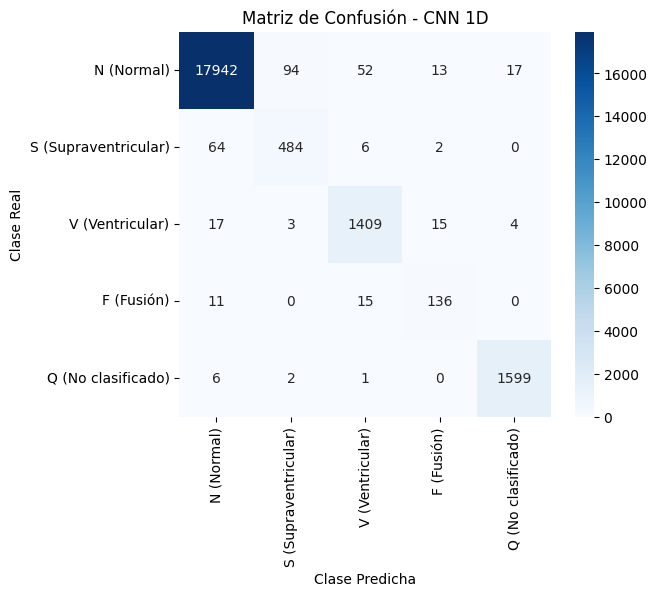

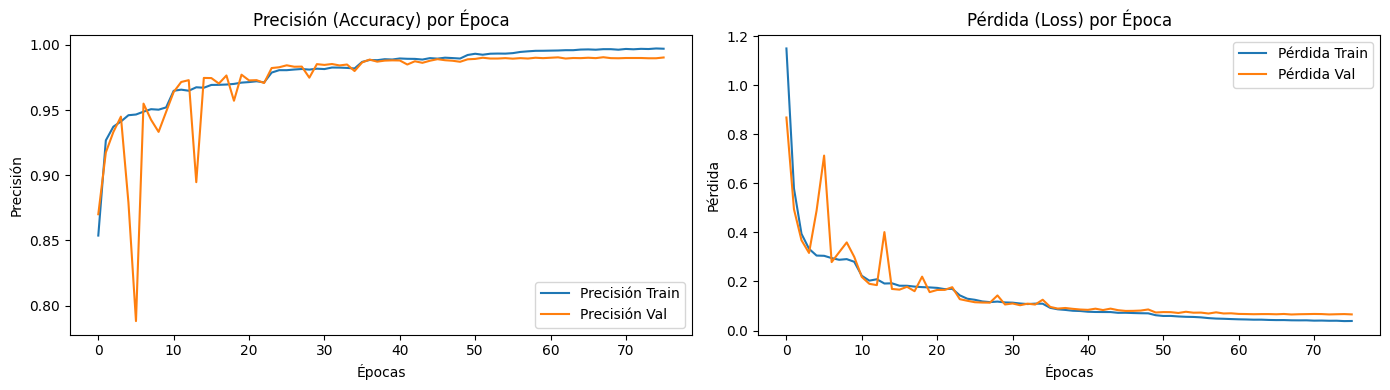

In [ ]:
# Evaluar con el conjunto de prueba
test_loss, test_acc = model.evaluate(X_test, y_test_cat)
print(f"Pérdida en Test: {test_loss:.4f}, Exactitud en Test: {test_acc:.4f}\n")

# Predecir sobre test
y_pred_probs = model.predict(X_test)
y_pred_classes = np.argmax(y_pred_probs, axis=1)

print("--------------------   Reporte de Clasificación  ------------------")
print(classification_report(y_test, y_pred_classes, target_names=clases_nombres))

# Matriz de Confusión
cm = confusion_matrix(y_test, y_pred_classes)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=clases_nombres, yticklabels=clases_nombres)
plt.title('Matriz de Confusión - CNN 1D')
plt.xlabel('Clase Predicha')
plt.ylabel('Clase Real')
plt.show()

# Gráficas del comportamiento durante el entrenamiento
plt.figure(figsize=(14, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Precisión Train')
plt.plot(history.history['val_accuracy'], label='Precisión Val')
plt.title('Precisión (Accuracy) por Época')
plt.xlabel('Épocas')
plt.ylabel('Precisión')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Pérdida Train')
plt.plot(history.history['val_loss'], label='Pérdida Val')
plt.title('Pérdida (Loss) por Época')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.legend()

plt.tight_layout()
plt.show()